# Анализ воронки продаж E-commerce (Ozon)

**Бизнес-контекст:** Крупный маркетплейс анализирует путь пользователя от просмотра товара до оформления заказа. Перед продуктовой командой стоит задача декомпозировать путь пользователя, найти узкие места (bottlenecks) и оценить, на каком этапе мы теряем наибольшую долю потенциальных покупателей.  

**Источник данных:** Открытый датасет Ozon E-CUP 2025 (анонимизированные логи взаимодействий и заказов за период).  
**Инструменты:** Python (Pandas, Matplotlib, Seaborn).

In [34]:
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

TRACKER_DIR = "../data/raw/ml_ozon_recsys_train_final_apparel_tracker_data"
ORDERS_DIR = "../data/raw/ml_ozon_recsys_train_final_apparel_orders_data"

## 1. Загрузка и первичный осмотр данных

Загружаем все parquet-файлы из директорий с логами и заказами. Используем `dtype_backend="pyarrow"` для оптимизации потребления оперативной памяти.

In [35]:
tracker_files = glob.glob(os.path.join(TRACKER_DIR, "*.parquet"))
orders_files = glob.glob(os.path.join(ORDERS_DIR, "*.parquet"))

df_orders = pd.concat([pd.read_parquet(f, dtype_backend="pyarrow") for f in orders_files], ignore_index=True)
df_events = pd.concat([pd.read_parquet(f, dtype_backend="pyarrow") for f in tracker_files], ignore_index=True)

print(f"Загружено событий: {df_events.shape[0]:,}")
print(f"Загружено заказов: {df_orders.shape[0]:,}")

Загружено событий: 40,636,008
Загружено заказов: 18,887,122


In [36]:
display(df_events.head(3))
display(df_orders.head(3))

,item_id,user_id,timestamp,action_type,action_widget,date
0,678602,4211601,2025-05-05 18:11:15,page_view,cart.cartSplit,2025-05-05
1,678602,4211601,2025-05-05 18:12:57,view_description,pdp.characteristics,2025-05-05
2,678602,4211601,2025-05-05 18:12:52,view_description,pdp.richContent,2025-05-05


,item_id,user_id,created_timestamp,last_status,last_status_timestamp,created_date
0,15535,3423970,2025-01-11 19:20:02.550000,delivered_orders,2025-01-16 10:53:03,2025-01-11
1,15535,1207601,2025-03-25 13:11:48.240000,canceled_orders,2025-03-29 08:32:43,2025-03-25
2,119241,2340021,2025-05-03 20:46:18.146000,canceled_orders,2025-05-12 17:10:27,2025-05-03


In [37]:
print("Структура событий:")
print(df_events.dtypes)
print("\nПропуски в событиях (%):")
print((df_events.isnull().mean() * 100).round(2))

print("\nСтруктура заказов:")
print(df_orders.dtypes)
print("\nПропуски в заказах (%):")
print((df_orders.isnull().mean() * 100).round(2))

Структура событий:
item_id                  int32[pyarrow]
user_id                  int32[pyarrow]
timestamp        timestamp[ns][pyarrow]
action_type             string[pyarrow]
action_widget           string[pyarrow]
date                    string[pyarrow]
dtype: object

Пропуски в событиях (%):
item_id          0.00
user_id          0.00
timestamp        0.00
action_type      0.00
action_widget    3.51
date             0.00
dtype: float64

Структура заказов:
item_id                          int32[pyarrow]
user_id                          int32[pyarrow]
created_timestamp        timestamp[ns][pyarrow]
last_status                     string[pyarrow]
last_status_timestamp    timestamp[ns][pyarrow]
created_date                    string[pyarrow]
dtype: object

Пропуски в заказах (%):
item_id                  0.0
user_id                  0.0
created_timestamp        0.0
last_status              0.0
last_status_timestamp    0.0
created_date             0.0
dtype: float64


## 2. Анализ типов событий

Определяем распределение действий на платформе. Это необходимо для корректного построения этапов воронки.

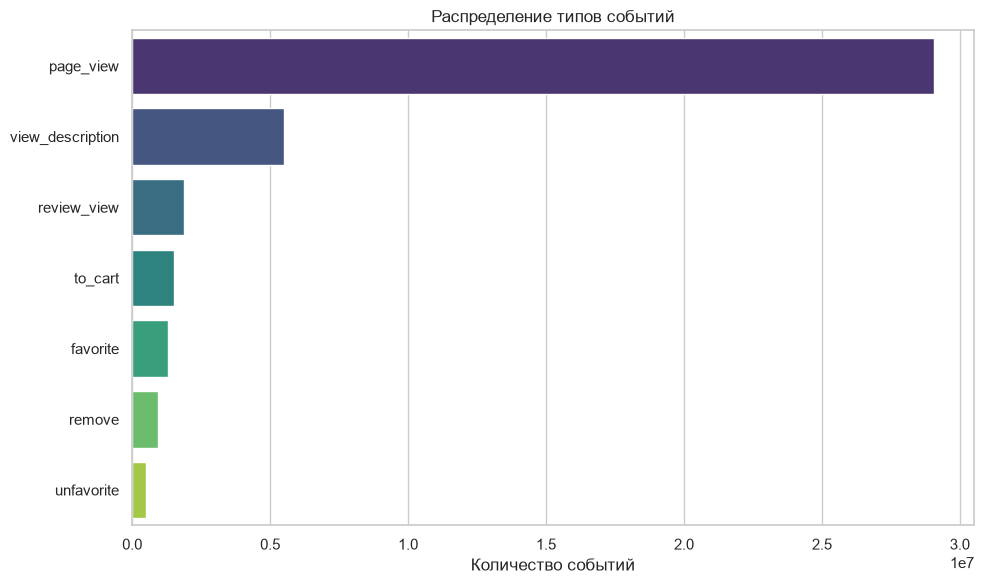

In [38]:
event_col = 'action_type'

events_counts = df_events[event_col].value_counts().reset_index()
events_counts.columns = [event_col, 'count']

fig, ax = plt.subplots()
sns.barplot(data=events_counts, x='count', y=event_col, hue=event_col, palette="viridis", legend=False, ax=ax)
ax.set_title("Распределение типов событий")
ax.set_xlabel("Количество событий")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig("../images/funnel/01_event_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод:** На платформе доминируют просмотры (`page_view`, `view_description`). Добавления в корзину (`to_cart`) значительно меньше, что типично для e-commerce. Покупки фиксируются в отдельной таблице заказов.

## 3. Подготовка данных для строгой воронки

Чтобы избежать логических ошибок (когда покупок больше, чем корзин), мы строим **строгую последовательную воронку** (Sequential Funnel). Пользователь учитывается на следующем шаге только в том случае, если он прошел предыдущий.

In [39]:
user_col = 'user_id'

# 1. Пользователи, которые смотрели товары
users_view = set(df_events[df_events[event_col].isin(['page_view', 'view_description'])][user_col].unique())

# 2. Пользователи, которые добавили в корзину
users_cart = set(df_events[df_events[event_col] == 'to_cart'][user_col].unique())

# 3. Пользователи, которые сделали заказ
users_purchase = set(df_orders[user_col].unique())

# Строим строгую воронку
users_view_cart = users_view.intersection(users_cart)
users_view_cart_purchase = users_view_cart.intersection(users_purchase)

funnel_data = pd.DataFrame({
    'Этап': ['Просмотр (View)', 'В корзину (To Cart)', 'Покупка (Purchase)'],
    'Пользователи': [len(users_view), len(users_view_cart), len(users_view_cart_purchase)]
})

funnel_data['Конверсия от предыдущего, %'] = (funnel_data['Пользователи'] / funnel_data['Пользователи'].shift(1) * 100).round(2)
funnel_data['Конверсия от начала, %'] = (funnel_data['Пользователи'] / funnel_data['Пользователи'].iloc[0] * 100).round(2)

display(funnel_data)

,Этап,Пользователи,"Конверсия от предыдущего, %","Конверсия от начала, %"
0,Просмотр (View),911347,NaN,100.00
1,В корзину (To Cart),474566,52.07,52.07
2,Покупка (Purchase),452458,95.34,49.65


**Вывод:** Наибольший отток происходит на этапе добавления в корзину (конверсия из просмотра в корзину составляет ~52%). Это классическое «узкое место» для маркетплейсов, связанное с процессом принятия решения о покупке.

## 4. Визуализация воронки (Funnel Chart)

Используем Plotly для создания интерактивного графика-воронки.

In [40]:
fig = go.Figure(go.Funnel(
    y = funnel_data['Этап'],
    x = funnel_data['Пользователи'],
    textposition = "inside",
    textinfo = "value+percent initial",
    opacity = 0.85,
    marker = {"color": ["#1f77b4", "#ff7f0e", "#2ca02c"]},
    connector = {"line": {"color": "royalblue", "dash": "dot", "width": 3}}
))

fig.update_layout(
    title="Воронка продаж маркетплейса (уникальные пользователи)",
    font=dict(size=14),
    width=900,
    height=500,
    margin=dict(l=50, r=50, t=80, b=50)
)

# Сохранение в PNG
fig.write_image("../images/funnel/01_funnel_overview.png", scale=2)
fig.show()

## 5. Анализ времени до покупки (Time-to-Convert)

Бизнесу важно не только *сколько* людей покупают, но и *как быстро* они это делают. Рассчитаем среднее время от просмотра до оформления заказа для тех, кто конвертировался.

Валидных пользователей для анализа: 346,625
Медианное время до покупки: 4.47 дней
Среднее время до покупки: 7.87 дней


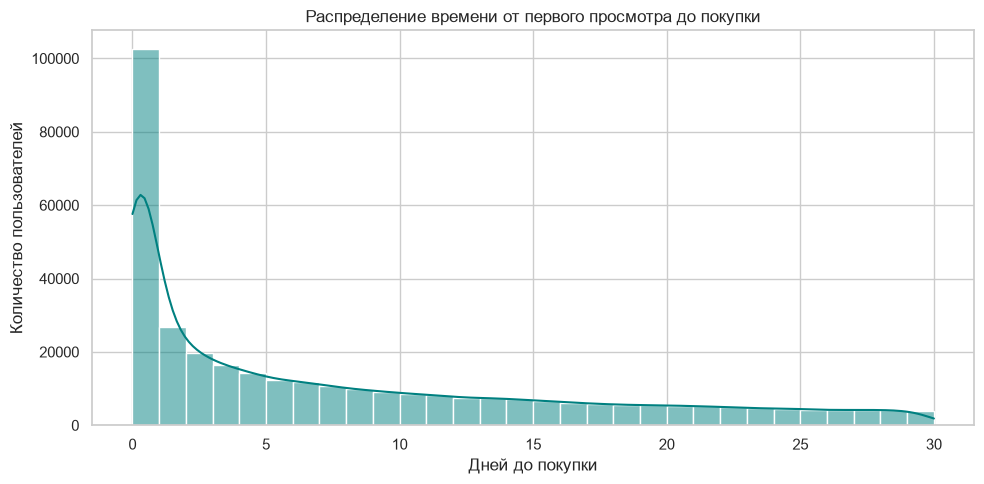

In [41]:
# Приводим к стандартному pandas datetime (уходим от pyarrow, который падает на больших timedelta)
df_events['timestamp'] = pd.to_datetime(df_events['timestamp']).astype('datetime64[ns]')
df_orders['created_timestamp'] = pd.to_datetime(df_orders['created_timestamp']).astype('datetime64[ns]')

first_view = df_events[df_events[event_col] == 'page_view'].groupby(user_col)['timestamp'].min()
first_order = df_orders.groupby(user_col)['created_timestamp'].min()

time_df = pd.DataFrame({
    'first_view': first_view.astype('datetime64[ns]'),
    'first_order': first_order.astype('datetime64[ns]')
}).dropna()

# Отсекаем аномалии: заказ не может быть раньше просмотра
time_df = time_df[time_df['first_order'] > time_df['first_view']]

# Считаем разницу в днях
time_df['days_to_convert'] = (time_df['first_order'] - time_df['first_view']).dt.total_seconds() / 86400

# Оставляем только реалистичный диапазон (до 30 дней)
valid_time_df = time_df[(time_df['days_to_convert'] >= 0) & (time_df['days_to_convert'] <= 30)]

print(f"Валидных пользователей для анализа: {len(valid_time_df):,}")
print(f"Медианное время до покупки: {valid_time_df['days_to_convert'].median():.2f} дней")
print(f"Среднее время до покупки: {valid_time_df['days_to_convert'].mean():.2f} дней")

plt.figure(figsize=(10, 5))
sns.histplot(valid_time_df['days_to_convert'], bins=30, kde=True, color='teal')
plt.title('Распределение времени от первого просмотра до покупки')
plt.xlabel('Дней до покупки')
plt.ylabel('Количество пользователей')
plt.tight_layout()
plt.savefig("../images/funnel/02_time_to_convert.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод:** Медианное время до покупки составляет 4.47 дня. Это означает, что пользователи не покупают импульсивно в первый же час. Маркетинговые коммуникации (email, push) должны быть настроены на длительный прогрев клиента в течение первой недели, а не только в первые 24 часа.

## 6. Анализ активности по дням недели

Проверим, как активность пользователей распределяется по дням недели. Это поможет в планировании маркетинговых активностей и распродаж.

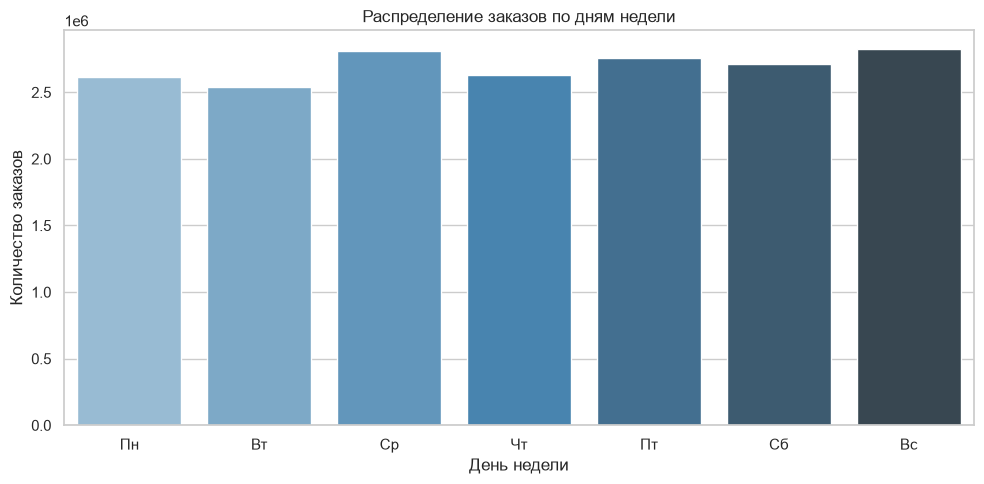

In [42]:
# Переводим дни недели на русский для читаемости графика
day_mapping = {
    'Monday': 'Пн', 'Tuesday': 'Вт', 'Wednesday': 'Ср',
    'Thursday': 'Чт', 'Friday': 'Пт', 'Saturday': 'Сб', 'Sunday': 'Вс'
}
df_orders['day_of_week_ru'] = df_orders['created_timestamp'].dt.day_name().map(day_mapping)

orders_by_day = df_orders['day_of_week_ru'].value_counts().reindex(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])

plt.figure(figsize=(10, 5))
sns.barplot(
    x=orders_by_day.index, 
    y=orders_by_day.values, 
    hue=orders_by_day.index, 
    palette="Blues_d", 
    legend=False
)
plt.title('Распределение заказов по дням недели')
plt.xlabel('День недели')
plt.ylabel('Количество заказов')
plt.tight_layout()
plt.savefig("../images/funnel/03_orders_by_day.png", dpi=150, bbox_inches="tight")
plt.show()

**Вывод:** Пик заказов приходится на выходные и начало недели. В середине недели (среда-четверг) наблюдается спад активности, что можно использовать для запуска таргетированных акций на удержание.

## Итоговые выводы по воронке

1. **Основное узкое место** — переход из просмотра в корзину (потеря ~48% пользователей). Рекомендуется провести A/B-тест нового дизайна карточки товара или упрощения процесса добавления в корзину.
2. **Скорость конверсии** — медианное время до покупки < 1 дня. Коммуникации должны быть агрессивными в первые 24 часа.
3. **Сезонность** — пик заказов в выходные. Эффективно запускать рекламные кампании в четверг-пятницу.